# Demographic vs Behaviour-Based Customer Segmentation: A Stability-Tested, Externally Validated Comparison
**Dataset:** `marketing_campaign.csv` (tab-separated, 2,240 customers, 29 columns).
**Dataset provenance:** NOT specified in the files supplied by the group (to be documented by the group).
**Task (from group sheet):** compare demographic-only and behaviour-based segmentation; feature scaling, PCA where justified,
K-Means and hierarchical clustering; internal metrics and stability; variable differentiation; segment-specific marketing actions.

**Research questions (proposed)**
- RQ1: How do demographic-only (D) and behaviour-based (B) segmentations compare on internal quality (Silhouette, Davies-Bouldin, Calinski-Harabasz)?
- RQ2: How stable are the segmentations across random seeds and subsamples (Adjusted Rand Index)?
- RQ3: How much do D and B segmentations agree, and which variables differentiate the clusters?
- RQ4: Which segmentation better separates customers on *external* criteria not used for clustering (campaign response, spending)?

## 1. Imports, seed, environment

In [1]:
import os, sys, platform, warnings, itertools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score, silhouette_samples)
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
print("Python", platform.python_version())
for m in (np, pd, scipy, sklearn, matplotlib, sns):
    print(m.__name__, m.__version__)
print("Random seed:", SEED)

CANDIDATES = ["marketing_campaign.csv", "/mnt/user-data/uploads/marketing_campaign.csv"]
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))
OUT = os.environ.get("PROJECT_OUT", "outputs")
os.makedirs(f"{OUT}/figs", exist_ok=True); os.makedirs(f"{OUT}/tables", exist_ok=True)

def save_table(df, name):
    df.to_csv(f"{OUT}/tables/{name}.csv")
def save_fig(name):
    plt.tight_layout(); plt.savefig(f"{OUT}/figs/{name}.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close()

Python 3.12.3
numpy 2.4.4
pandas 3.0.2
scipy 1.17.1
sklearn 1.8.0
matplotlib 3.10.8
seaborn 0.13.2
Random seed: 42


## 2. Load dataset and overview

In [2]:
raw = pd.read_csv(DATA_PATH, sep="\t")
print("Shape:", raw.shape)
print("Duplicate rows (all columns):", raw.duplicated().sum())
print("Duplicate rows (ignoring ID):", raw.drop(columns="ID").duplicated().sum())
print("ID unique:", raw["ID"].is_unique)
miss = raw.isna().sum(); print("Missing values:\n", miss[miss > 0])
print("\nConstant columns:", [c for c in raw.columns if raw[c].nunique() == 1])
desc = raw.describe().T
save_table(desc, "T1_descriptives_raw")
print(desc[["count", "mean", "std", "min", "50%", "max"]].round(2).to_string())

Shape: (2240, 29)
Duplicate rows (all columns): 0
Duplicate rows (ignoring ID): 182
ID unique: True
Missing values:
 Income    24
dtype: int64

Constant columns: ['Z_CostContact', 'Z_Revenue']
                      count      mean       std     min      50%       max
ID                   2240.0   5592.16   3246.66     0.0   5458.5   11191.0
Year_Birth           2240.0   1968.81     11.98  1893.0   1970.0    1996.0
Income               2216.0  52247.25  25173.08  1730.0  51381.5  666666.0
Kidhome              2240.0      0.44      0.54     0.0      0.0       2.0
Teenhome             2240.0      0.51      0.54     0.0      0.0       2.0
Recency              2240.0     49.11     28.96     0.0     49.0      99.0
MntWines             2240.0    303.94    336.60     0.0    173.5    1493.0
MntFruits            2240.0     26.30     39.77     0.0      8.0     199.0
MntMeatProducts      2240.0    166.95    225.72     0.0     67.0    1725.0
MntFishProducts      2240.0     37.53     54.63     0.0  

## 3. Data quality and cleaning (rules fixed before modelling)
Reference date = latest `Dt_Customer` (dataset snapshot proxy; **assumption**, since the collection date is not documented).

In [3]:
df = raw.copy()
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
REF_DATE = df["Dt_Customer"].max()
df["Age"] = REF_DATE.year - df["Year_Birth"]
q1, q3 = df["Income"].quantile([.25, .75]); FENCE = q3 + 3 * (q3 - q1)   # Tukey extreme-outlier fence
rules = {
    "Implausible age (> 100 years)": df["Age"] > 100,
    f"Extreme income (> Tukey 3*IQR fence = {FENCE:,.0f})": df["Income"] > FENCE,
    "Invalid marital status label (Absurd/YOLO)": df["Marital_Status"].isin(["Absurd", "YOLO"]),
}
audit = pd.DataFrame({"rows_flagged": {k: int(v.sum()) for k, v in rules.items()}})
drop_mask = np.logical_or.reduce(list(rules.values()))
print(audit.to_string()); print("Total rows removed:", int(drop_mask.sum()))
save_table(audit, "T2_cleaning_audit")
df = df.loc[~drop_mask].copy()
print("Rows after cleaning:", len(df))
print("Missing Income remaining (imputed later inside pipeline):", int(df["Income"].isna().sum()))

                                                rows_flagged
Implausible age (> 100 years)                              3
Extreme income (> Tukey 3*IQR fence = 168,179)             1
Invalid marital status label (Absurd/YOLO)                 4
Total rows removed: 8
Rows after cleaning: 2232
Missing Income remaining (imputed later inside pipeline): 24


## 4. Feature engineering
Demographic set **D**: Age, Income, Education (ordinal), Partnered, Total_Children.
Behavioural set **B**: Recency, log(1+Total_Spend), channel purchase counts, deals, web visits.
**Combined set C** = D + B (extension). Campaign variables (`Response`, `AcceptedCmp*`, `Complain`) are NOT used for clustering; they are used only for external validation.

In [4]:
spend_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
# ASSUMPTION: '2n Cycle' treated as equivalent to Master (same ordinal level); not verifiable from provided files
edu_map = {"Basic": 1, "Graduation": 2, "2n Cycle": 3, "Master": 3, "PhD": 4}
df["Edu_ord"] = df["Education"].map(edu_map)
df["Partnered"] = df["Marital_Status"].isin(["Married", "Together"]).astype(int)
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]
df["Total_Spend"] = df[spend_cols].sum(axis=1)
df["Total_Spend_log"] = np.log1p(df["Total_Spend"])
df["Total_Purchases"] = df[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)
df["Tenure_days"] = (REF_DATE - df["Dt_Customer"]).dt.days
df["Campaigns_Accepted"] = df[[f"AcceptedCmp{i}" for i in range(1, 6)]].sum(axis=1)

DEMO = ["Age", "Income", "Edu_ord", "Partnered", "Total_Children"]
BEHAV = ["Recency", "Total_Spend_log", "NumDealsPurchases", "NumWebPurchases",
         "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth"]
COMB = DEMO + BEHAV
SETS = {"Demographic": DEMO, "Behavioural": BEHAV, "Combined": COMB}
print({k: len(v) for k, v in SETS.items()})

def build_X(dfx, cols, pca_var=None):
    """Median-impute -> standardise (-> optional PCA). Unsupervised: no target information is used."""
    X = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]).fit_transform(dfx[cols])
    if pca_var:
        X = PCA(n_components=pca_var, random_state=SEED).fit_transform(X)
    return X

{'Demographic': 5, 'Behavioural': 7, 'Combined': 12}


## 5. Exploratory data analysis

Skewness:
 Income                 0.35
Total_Spend            0.86
NumWebPurchases        1.38
NumCatalogPurchases    1.89
Age                    0.09


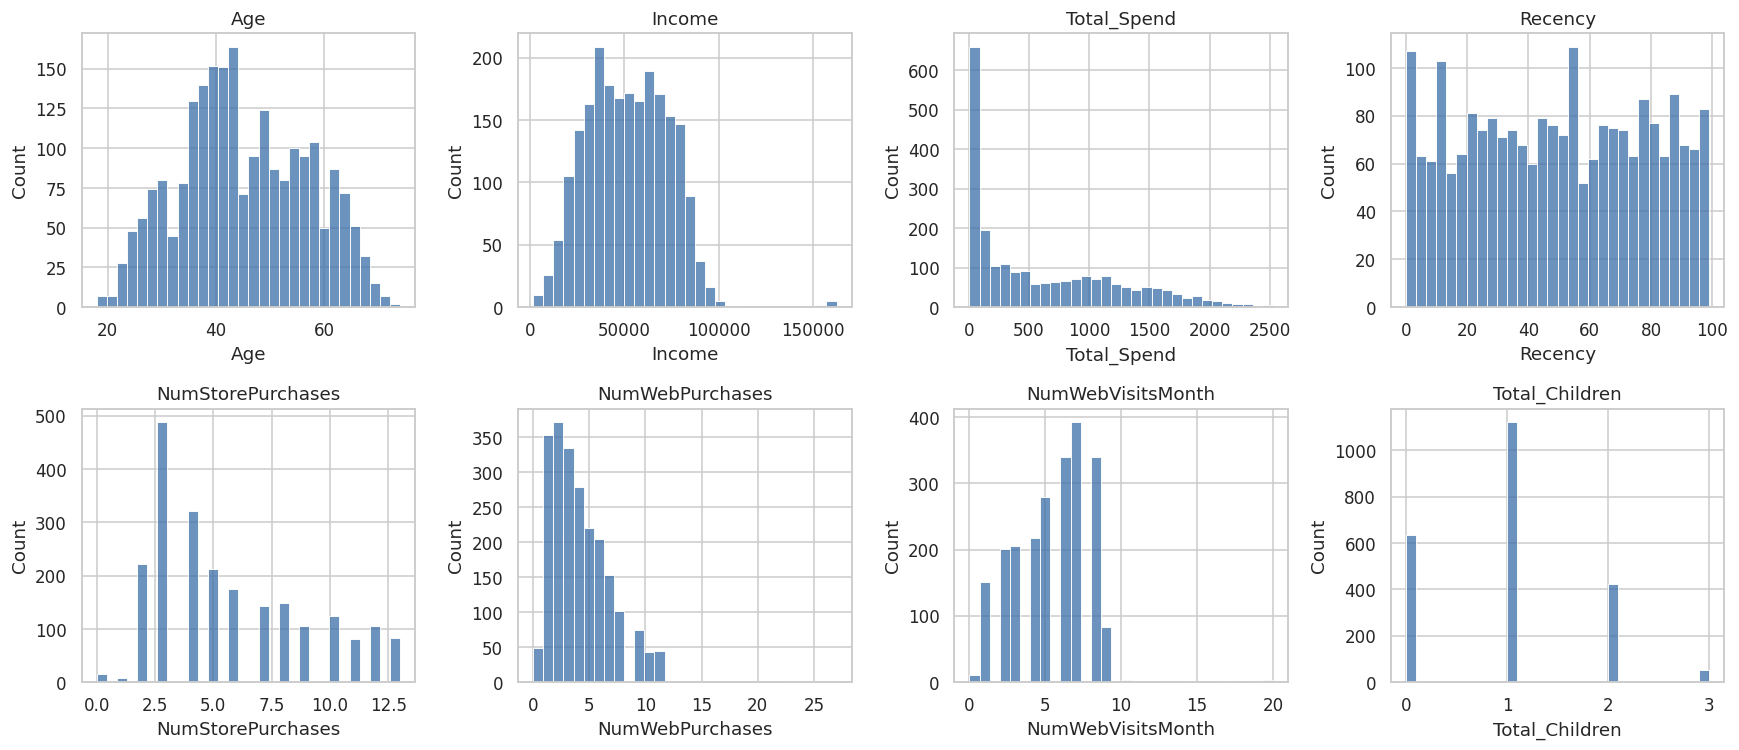

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), ["Age", "Income", "Total_Spend", "Recency", "NumStorePurchases", "NumWebPurchases", "NumWebVisitsMonth", "Total_Children"]):
    sns.histplot(df[c].dropna(), bins=30, ax=ax, color="#3B6EA8"); ax.set_title(c)
save_fig("F1_distributions")
sk = df[["Income", "Total_Spend", "NumWebPurchases", "NumCatalogPurchases", "Age"]].skew().round(2)
print("Skewness:\n", sk.to_string())

Mean |rho| within demographic: 0.103; within behavioural: 0.329; between blocks: 0.217


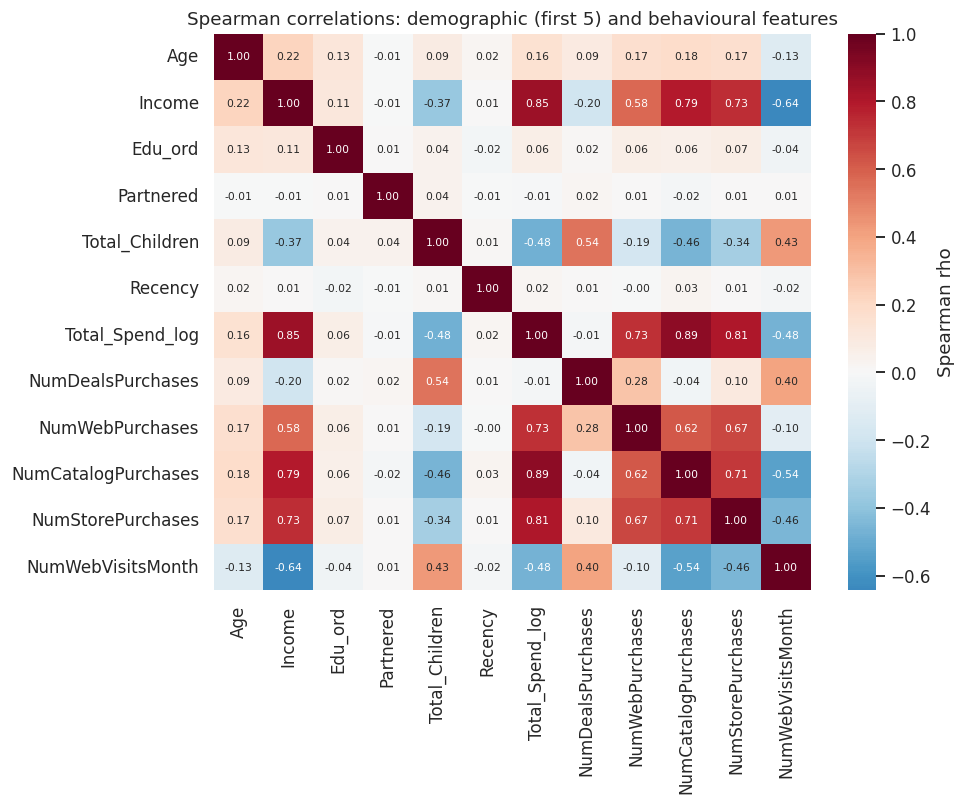

In [6]:
corr = df[COMB].corr(method="spearman")
plt.figure(figsize=(9, 7.5)); sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"label": "Spearman rho"})
plt.title("Spearman correlations: demographic (first 5) and behavioural features"); save_fig("F2_correlation")
Cd = corr.loc[DEMO, BEHAV].abs().values.mean()
Cwd = corr.loc[DEMO, DEMO].abs().values[np.triu_indices(len(DEMO), 1)].mean()
Cwb = corr.loc[BEHAV, BEHAV].abs().values[np.triu_indices(len(BEHAV), 1)].mean()
print(f"Mean |rho| within demographic: {Cwd:.3f}; within behavioural: {Cwb:.3f}; between blocks: {Cd:.3f}")

## 6. PCA: is it justified?
PCA is examined on each standardised feature set; it is used for (a) checking redundancy, (b) visualisation, and (c) a sensitivity variant (95% variance).

             n_features    PC1  PC1+PC2  n_PC_for_80%  n_PC_for_95%
Set                                                                
Demographic           5  0.279    0.517             4             5
Behavioural           7  0.441    0.644             4             6
Combined             12  0.343    0.485             6             9


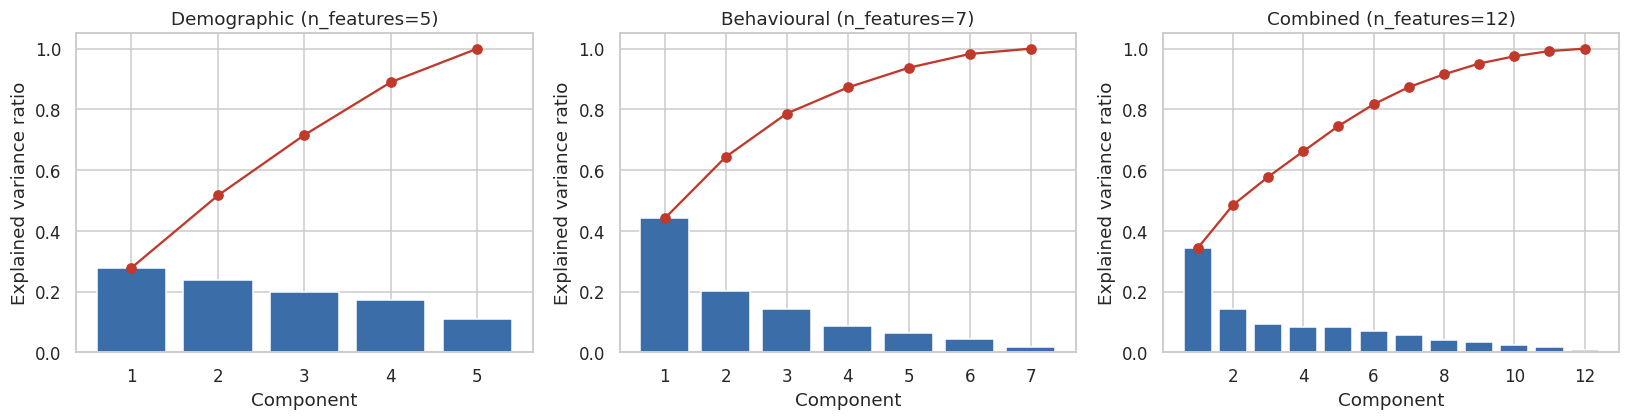

In [7]:
pca_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, cols) in zip(axes, SETS.items()):
    X = build_X(df, cols); p = PCA(random_state=SEED).fit(X)
    ev = p.explained_variance_ratio_; cum = np.cumsum(ev)
    ax.bar(range(1, len(ev) + 1), ev, color="#3B6EA8"); ax.plot(range(1, len(ev) + 1), cum, "o-", color="#C0392B")
    ax.set_title(f"{name} (n_features={len(cols)})"); ax.set_xlabel("Component"); ax.set_ylabel("Explained variance ratio")
    pca_rows.append({"Set": name, "n_features": len(cols), "PC1": ev[0], "PC1+PC2": cum[1],
                     "n_PC_for_80%": int(np.argmax(cum >= .80) + 1), "n_PC_for_95%": int(np.argmax(cum >= .95) + 1)})
save_fig("F3_pca_scree")
pca_tab = pd.DataFrame(pca_rows).set_index("Set"); save_table(pca_tab, "T3_pca"); print(pca_tab.round(3).to_string())

## 7. Choosing the number of clusters
A-priori rule (set before looking at results): k is searched over 2-8; **k >= 3 is required for managerial usefulness** (a binary split gives little targeting differentiation); among k in 3-8 select the k with the highest Silhouette, and report whether Davies-Bouldin agrees.


Demographic
    KM_inertia  KM_sil  KM_dbi    KM_ch  Ward_sil  Ward_dbi  Ward_ch
k                                                                  
2    8924.569   0.235   1.820  558.572     0.234     1.821  557.128
3    7539.763   0.207   1.616  535.130     0.183     1.767  466.953
4    6579.113   0.215   1.440  517.102     0.178     1.639  426.022
5    5920.218   0.220   1.499  492.760     0.195     1.729  414.639
6    5353.721   0.224   1.420  482.833     0.187     1.523  417.131
7    4877.186   0.236   1.323  477.709     0.201     1.403  409.096
8    4450.229   0.251   1.242  479.029     0.195     1.401  397.515

Behavioural
    KM_inertia  KM_sil  KM_dbi     KM_ch  Ward_sil  Ward_dbi   Ward_ch
k                                                                    
2   10110.722   0.335   1.228  1216.012     0.318     1.277  1112.073
3    8251.684   0.319   1.434   995.730     0.324     1.236   871.342
4    7500.050   0.236   1.483   804.447     0.278     1.735   707.890
5    6753.

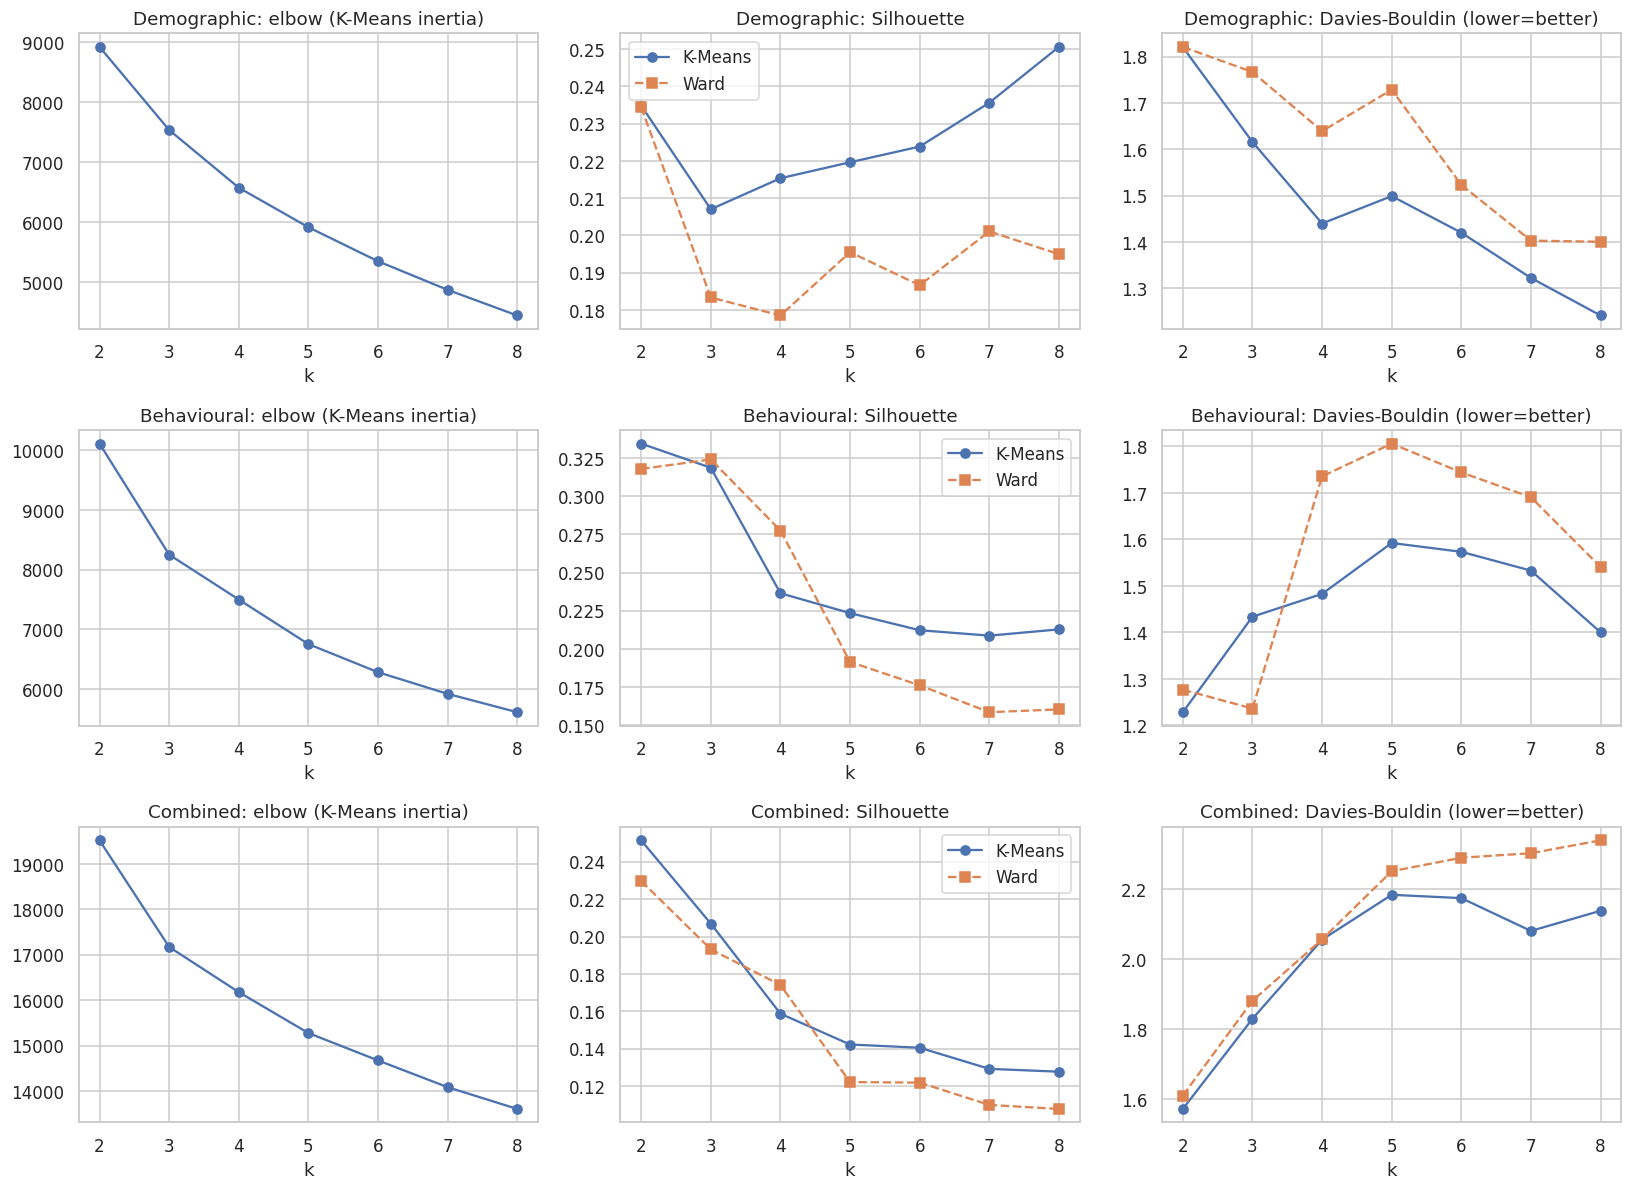

In [8]:
def eval_k(X, ks=range(2, 9)):
    rows = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
        wd = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        rows.append({"k": k, "KM_inertia": km.inertia_, "KM_sil": silhouette_score(X, km.labels_),
                     "KM_dbi": davies_bouldin_score(X, km.labels_), "KM_ch": calinski_harabasz_score(X, km.labels_),
                     "Ward_sil": silhouette_score(X, wd), "Ward_dbi": davies_bouldin_score(X, wd), "Ward_ch": calinski_harabasz_score(X, wd)})
    return pd.DataFrame(rows).set_index("k")

KTAB, XS = {}, {}
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for r, (name, cols) in enumerate(SETS.items()):
    XS[name] = build_X(df, cols); KTAB[name] = eval_k(XS[name]); t = KTAB[name]
    axes[r, 0].plot(t.index, t.KM_inertia, "o-"); axes[r, 0].set_title(f"{name}: elbow (K-Means inertia)")
    axes[r, 1].plot(t.index, t.KM_sil, "o-", label="K-Means"); axes[r, 1].plot(t.index, t.Ward_sil, "s--", label="Ward"); axes[r, 1].set_title(f"{name}: Silhouette"); axes[r, 1].legend()
    axes[r, 2].plot(t.index, t.KM_dbi, "o-", label="K-Means"); axes[r, 2].plot(t.index, t.Ward_dbi, "s--", label="Ward"); axes[r, 2].set_title(f"{name}: Davies-Bouldin (lower=better)")
    for a in axes[r]: a.set_xlabel("k")
save_fig("F4_k_selection")
for name, t in KTAB.items():
    save_table(t, f"T4_k_selection_{name}"); print(f"\n{name}\n", t.round(3).to_string())

K_SEL = {}
for name, t in KTAB.items():
    sub = t.loc[3:8]; K_SEL[name] = int(sub.KM_sil.idxmax())
    print(f"{name}: k selected (max KM silhouette, k>=3) = {K_SEL[name]}; k with min DBI (k>=3) = {int(sub.KM_dbi.idxmin())}; unconstrained best sil k = {int(t.KM_sil.idxmax())}")

### DEVIATION NOTE (post-hoc, disclosed)
The a-priori rule gave k = 8 for the Demographic set (its silhouette rises almost monotonically with k, i.e. no clear natural k) but k = 3 for the Behavioural and
Combined sets. Internal validity indices are **not comparable across different k**, so a fair D-vs-B comparison requires a **common k**.
The primary analysis therefore uses **k = 3 for all segmentations** (the k chosen by the rule for B and C, and a manageable number of segments).
Demographic at its own rule-selected k (= 8) is reported as a sensitivity analysis (Section 17). This choice was made after seeing the k-selection results.

In [9]:
K_USE = {name: 3 for name in SETS}
print("Primary analysis k:", K_USE, "| rule-selected k:", K_SEL)

Primary analysis k: {'Demographic': 3, 'Behavioural': 3, 'Combined': 3} | rule-selected k: {'Demographic': 8, 'Behavioural': 3, 'Combined': 3}


## 8. Final models: K-Means and hierarchical (Ward) at the selected k, plus linkage comparison

In [10]:
def relabel(labels, series):
    """Display-only relabelling: clusters numbered 1..k in ascending order of mean of `series` (ARI-invariant)."""
    order = pd.Series(series.values).groupby(labels).mean().sort_values().index
    m = {old: i + 1 for i, old in enumerate(order)}
    return np.array([m[l] for l in labels])

LAB = {}; rows = []
for name in SETS:
    X, k = XS[name], K_USE[name]
    ref = "Income" if name == "Demographic" else "Total_Spend"
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    wd = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    LAB[(name, "KMeans")] = relabel(km.labels_, df[ref]); LAB[(name, "Ward")] = relabel(wd, df[ref])
    for alg in ("KMeans", "Ward"):
        l = LAB[(name, alg)]; sizes = np.bincount(l)[1:]
        rows.append({"Segmentation": name, "Algorithm": alg, "k": k, "Silhouette": silhouette_score(X, l), "Davies-Bouldin": davies_bouldin_score(X, l),
                     "Calinski-Harabasz": calinski_harabasz_score(X, l), "Smallest cluster %": 100 * sizes.min() / len(l), "Sizes": list(sizes)})
    rows[-2]["ARI KM vs Ward"] = rows[-1]["ARI KM vs Ward"] = adjusted_rand_score(LAB[(name, "KMeans")], LAB[(name, "Ward")])
T_MAIN = pd.DataFrame(rows).set_index(["Segmentation", "Algorithm"]); save_table(T_MAIN, "T5_main_models"); print(T_MAIN.round(3).to_string())

# linkage comparison (cophenetic correlation) at selected k
lrows = []
for name in SETS:
    X, k = XS[name], K_USE[name]; d = pdist(X)
    for method in ("ward", "average", "complete"):
        Z = linkage(X, method=method); c, _ = cophenet(Z, d)
        l = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X)
        lrows.append({"Segmentation": name, "Linkage": method, "Cophenetic r": c, "Silhouette": silhouette_score(X, l),
                      "Davies-Bouldin": davies_bouldin_score(X, l), "Smallest cluster %": 100 * np.bincount(l).min() / len(l)})
T_LINK = pd.DataFrame(lrows).set_index(["Segmentation", "Linkage"]); save_table(T_LINK, "T6_linkage"); print(T_LINK.round(3).to_string())

                        k  Silhouette  Davies-Bouldin  Calinski-Harabasz  Smallest cluster %             Sizes  ARI KM vs Ward
Segmentation Algorithm                                                                                                        
Demographic  KMeans     3       0.217           1.606            538.257              26.971   [999, 602, 631]           0.516
             Ward       3       0.183           1.767            466.953              22.088   [950, 789, 493]           0.516
Behavioural  KMeans     3       0.319           1.434            995.730              24.866   [975, 555, 702]           0.661
             Ward       3       0.324           1.236            871.342               9.409  [1058, 210, 964]           0.661
Combined     KMeans     3       0.207           1.830            623.929              26.658   [953, 595, 684]           0.696
             Ward       3       0.193           1.881            575.821              21.147   [961, 799, 472] 

## 9. Matched-k comparison (fair comparison of D vs B at the same k)

In [11]:
mk = []
for k in (3, 4, 5):
    for name in SETS:
        t = KTAB[name].loc[k]
        mk.append({"k": k, "Segmentation": name, "KM Silhouette": t.KM_sil, "KM DB": t.KM_dbi, "Ward Silhouette": t.Ward_sil, "Ward DB": t.Ward_dbi})
T_MK = pd.DataFrame(mk).set_index(["k", "Segmentation"]); save_table(T_MK, "T7_matched_k"); print(T_MK.round(3).to_string())

                KM Silhouette  KM DB  Ward Silhouette  Ward DB
k Segmentation                                                
3 Demographic           0.207  1.616            0.183    1.767
  Behavioural           0.319  1.434            0.324    1.236
  Combined              0.207  1.830            0.193    1.881
4 Demographic           0.215  1.440            0.178    1.639
  Behavioural           0.236  1.483            0.278    1.735
  Combined              0.159  2.056            0.174    2.057
5 Demographic           0.220  1.499            0.195    1.729
  Behavioural           0.223  1.592            0.191    1.806
  Combined              0.142  2.184            0.122    2.251


## 10. Stability analysis
(a) **Seed stability:** 30 single-initialisation K-Means runs (seeds 0-29); mean pairwise Adjusted Rand Index (ARI).
(b) **Subsample stability:** 100 random 80% subsamples (without replacement); each is re-clustered and compared (ARI) with the full-data reference partition restricted to the same rows. K-Means and Ward.
(c) **Stability across k:** K-Means subsample ARI, 30 subsamples, k = 2-8.

                                                                   k  Mean ARI     SD  Min / P5
Segmentation Test                                       Algorithm                              
Demographic  Seed (30 runs, pairwise ARI)               KMeans     3     0.445  0.289     0.032
             Subsample 80% (100 runs, ARI vs reference) KMeans     3     0.833  0.157     0.596
                                                        Ward       3     0.616  0.204     0.212
Behavioural  Seed (30 runs, pairwise ARI)               KMeans     3     0.884  0.195     0.417
             Subsample 80% (100 runs, ARI vs reference) KMeans     3     0.977  0.020     0.939
                                                        Ward       3     0.607  0.088     0.488
Combined     Seed (30 runs, pairwise ARI)               KMeans     3     0.987  0.008     0.966
             Subsample 80% (100 runs, ARI vs reference) KMeans     3     0.976  0.015     0.947
                                        

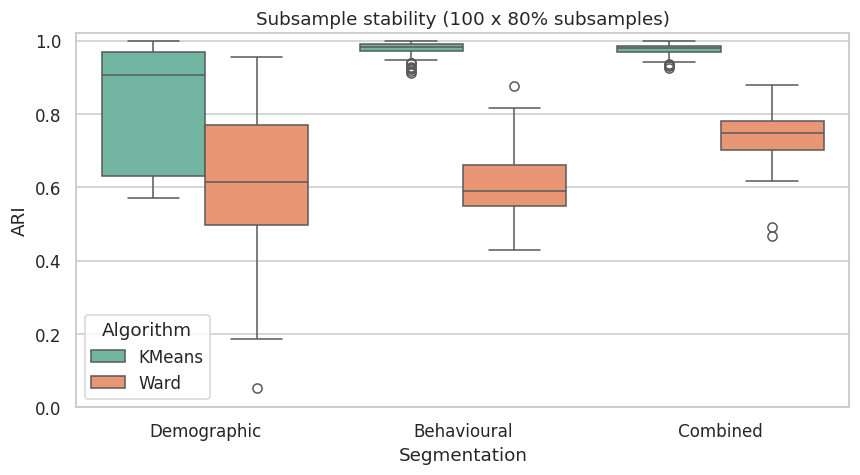

In [12]:
def seed_stability(X, k, seeds=range(30)):
    labs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit_predict(X) for s in seeds]
    aris = [adjusted_rand_score(a, b) for a, b in itertools.combinations(labs, 2)]
    return np.mean(aris), np.std(aris), np.min(aris)

def subsample_stability(X, k, ref, alg, B=100, frac=.8, seed=SEED):
    rng = np.random.default_rng(seed); n = len(X); out = []
    for _ in range(B):
        idx = rng.choice(n, int(frac * n), replace=False)
        if alg == "KMeans": l = KMeans(n_clusters=k, n_init=10, random_state=int(rng.integers(1e6))).fit_predict(X[idx])
        else: l = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X[idx])
        out.append(adjusted_rand_score(ref[idx], l))
    return np.array(out)

srows = []; SUB = {}
for name in SETS:
    X, k = XS[name], K_USE[name]
    m, s, mn = seed_stability(X, k)
    srows.append({"Segmentation": name, "k": k, "Test": "Seed (30 runs, pairwise ARI)", "Algorithm": "KMeans", "Mean ARI": m, "SD": s, "Min / P5": mn})
    for alg in ("KMeans", "Ward"):
        a = subsample_stability(X, k, LAB[(name, alg)], alg); SUB[(name, alg)] = a
        srows.append({"Segmentation": name, "k": k, "Test": "Subsample 80% (100 runs, ARI vs reference)", "Algorithm": alg, "Mean ARI": a.mean(), "SD": a.std(), "Min / P5": np.percentile(a, 5)})
T_STAB = pd.DataFrame(srows).set_index(["Segmentation", "Test", "Algorithm"]); save_table(T_STAB, "T8_stability"); print(T_STAB.round(3).to_string())

plt.figure(figsize=(8, 4.5))
dd = pd.DataFrame([{"Segmentation": n, "Algorithm": a, "ARI": v} for (n, a), arr in SUB.items() for v in arr])
sns.boxplot(data=dd, x="Segmentation", y="ARI", hue="Algorithm", palette="Set2"); plt.title("Subsample stability (100 x 80% subsamples)"); plt.ylim(0, 1.02)
save_fig("F5_stability_boxplot")

krows = []
for name in ("Demographic", "Behavioural"):
    X = XS[name]
    for k in range(2, 9):
        ref = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X)
        a = subsample_stability(X, k, ref, "KMeans", B=30)
        krows.append({"Segmentation": name, "k": k, "Mean ARI": a.mean(), "SD": a.std()})
T_KSTAB = pd.DataFrame(krows).pivot(index="k", columns="Segmentation", values="Mean ARI"); save_table(T_KSTAB, "T9_stability_by_k"); print(T_KSTAB.round(3).to_string())

## 11. Agreement between segmentations

In [13]:
ag = []
pairs = [("Demographic", "Behavioural"), ("Demographic", "Combined"), ("Behavioural", "Combined")]
for a, b in pairs:
    for alg in ("KMeans", "Ward"):
        ag.append({"Pair": f"{a} vs {b}", "Algorithm": alg, "ARI": adjusted_rand_score(LAB[(a, alg)], LAB[(b, alg)]), "NMI": normalized_mutual_info_score(LAB[(a, alg)], LAB[(b, alg)])})
T_AGR = pd.DataFrame(ag).set_index(["Pair", "Algorithm"]); save_table(T_AGR, "T10_agreement"); print(T_AGR.round(3).to_string())
ct = pd.crosstab(pd.Series(LAB[("Demographic", "KMeans")], name="Demographic cluster"), pd.Series(LAB[("Behavioural", "KMeans")], name="Behavioural cluster"))
save_table(ct, "T11_crosstab_D_vs_B"); print(ct.to_string())

                                        ARI    NMI
Pair                       Algorithm              
Demographic vs Behavioural KMeans     0.276  0.274
                           Ward       0.097  0.100
Demographic vs Combined    KMeans     0.309  0.322
                           Ward       0.107  0.115
Behavioural vs Combined    KMeans     0.873  0.808
                           Ward       0.545  0.547
Behavioural cluster    1    2    3
Demographic cluster               
1                    621  295   83
2                    337  187   78
3                     17   73  541


## 12. Cluster profiling (K-Means; primary algorithm fixed a priori)

In [14]:
PROFILE = ["Age", "Income", "Edu_ord", "Partnered", "Total_Children", "Tenure_days", "Recency", "Total_Spend", "MntWines", "MntMeatProducts",
           "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth",
           "Campaigns_Accepted", "Response", "Complain"]
PROFS = {}
for name in SETS:
    d = df.copy(); d["Cluster"] = LAB[(name, "KMeans")]
    p = d.groupby("Cluster")[PROFILE].mean().T; p["Overall"] = df[PROFILE].mean()
    p.loc["Cluster size (n)"] = list(d["Cluster"].value_counts().sort_index()) + [len(d)]
    p.loc["Cluster size (%)"] = list((100 * d["Cluster"].value_counts(normalize=True).sort_index())) + [100.0]
    PROFS[name] = p; save_table(p, f"T12_profile_{name}"); print(f"\n=== {name} (K-Means, k={K_USE[name]}) ===\n", p.round(2).to_string())


=== Demographic (K-Means, k=3) ===
 Cluster                     1         2         3   Overall
Age                     43.92     44.75     47.34     45.11
Income               41490.63  43915.82  76003.27  51943.52
Edu_ord                  2.59      2.62      2.82      2.66
Partnered                1.00      0.00      0.70      0.65
Total_Children           1.27      1.19      0.23      0.95
Tenure_days            356.23    359.98    343.09    353.53
Recency                 49.57     48.44     49.18     49.15
Total_Spend            302.49    384.31   1296.69    605.62
MntWines               165.99    209.76    612.63    304.07
MntMeatProducts         62.86     81.18    413.61    166.96
NumDealsPurchases        2.77      2.65      1.30      2.32
NumWebPurchases          3.54      3.83      5.20      4.09
NumCatalogPurchases      1.39      1.73      5.56      2.66
NumStorePurchases        4.74      4.98      8.25      5.79
NumWebVisitsMonth        6.28      6.15      3.01      5.32
Cam

## 13. Which variables differentiate the clusters? (effect size eta-squared + Kruskal-Wallis)
Variables used as clustering inputs differ by construction; the informative comparison is for variables **not** used by a segmentation (cross-block).

In [15]:
def eta_sq(x, g):
    x = np.asarray(x, float); g = np.asarray(g); gm = x.mean()
    ssb = sum((g == c).sum() * (x[g == c].mean() - gm) ** 2 for c in np.unique(g)); sst = ((x - gm) ** 2).sum()
    return ssb / sst if sst > 0 else np.nan

DIFF_VARS = DEMO + ["Tenure_days", "Recency", "Total_Spend", "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth", "Campaigns_Accepted"]
drows = []
for v in DIFF_VARS:
    row = {"Variable": v, "Block": "Demographic" if v in DEMO else "Behavioural/other"}
    for name in ("Demographic", "Behavioural"):
        x = df[v]; ok = x.notna().values; g = LAB[(name, "KMeans")]
        row[f"eta2 | {name} clusters"] = eta_sq(x[ok], g[ok])
        row[f"KW p | {name}"] = stats.kruskal(*[x[ok][g[ok] == c] for c in np.unique(g)]).pvalue
        row[f"input to {name}?"] = v in SETS[name] or (v == "Total_Spend" and "Total_Spend_log" in SETS[name])
    drows.append(row)
T_DIFF = pd.DataFrame(drows).set_index("Variable"); save_table(T_DIFF, "T13_differentiation"); print(T_DIFF.round(3).to_string())
summ = {}
for name in ("Demographic", "Behavioural"):
    for blk, cond in (("demographic vars (non-input only)", lambda r: r["Block"] == "Demographic"), ("behavioural/other vars (non-input only)", lambda r: r["Block"] != "Demographic")):
        sel = T_DIFF[(T_DIFF.apply(cond, axis=1)) & (~T_DIFF[f"input to {name}?"])]
        summ[(name + " clusters", blk)] = sel[f"eta2 | {name} clusters"].mean() if len(sel) else np.nan
print("\nMean eta2 on NON-INPUT variables:"); print(pd.Series(summ).round(3).to_string())

                                 Block  eta2 | Demographic clusters  KW p | Demographic  input to Demographic?  eta2 | Behavioural clusters  KW p | Behavioural  input to Behavioural?
Variable                                                                                                                                                                              
Age                        Demographic                        0.015               0.000                   True                        0.038               0.000                  False
Income                     Demographic                        0.497               0.000                   True                        0.612               0.000                  False
Edu_ord                    Demographic                        0.014               0.000                   True                        0.005               0.012                  False
Partnered                  Demographic                        0.741               0.0

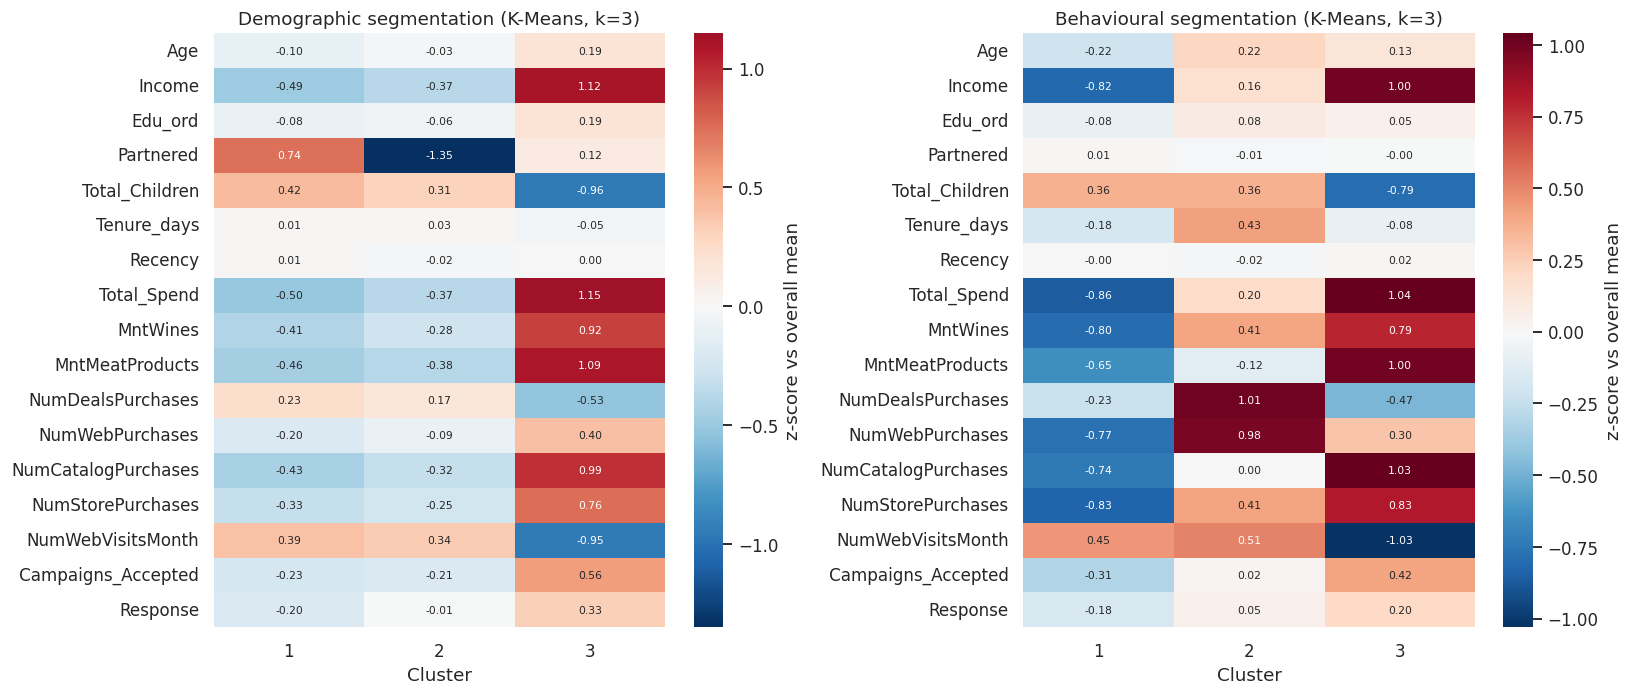

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, name in zip(axes, ("Demographic", "Behavioural")):
    d = df.copy(); d["Cluster"] = LAB[(name, "KMeans")]
    z = d.groupby("Cluster")[PROFILE[:-1]].mean(); z = (z - df[PROFILE[:-1]].mean()) / df[PROFILE[:-1]].std()
    sns.heatmap(z.T, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "z-score vs overall mean"}); ax.set_title(f"{name} segmentation (K-Means, k={K_USE[name]})")
save_fig("F6_profile_heatmap")

## 14. External validation using variables NOT used for clustering (campaign response)

              k  Min response %  Max response %  Response spread (pp)  Cramers V (Response)  chi2 p  eta2 (Campaigns_Accepted)  eta2 (Total_Spend)
Segmentation                                                                                                                                      
Demographic   3          7.8078         26.4659               18.6581                0.2184     0.0                     0.1254              0.5225
Behavioural   3          8.6154         22.0798               13.4644                0.1646     0.0                     0.0975              0.6745
Combined      3          9.0241         23.9766               14.9525                0.1784     0.0                     0.1066              0.6852
Overall response rate: 14.87 %


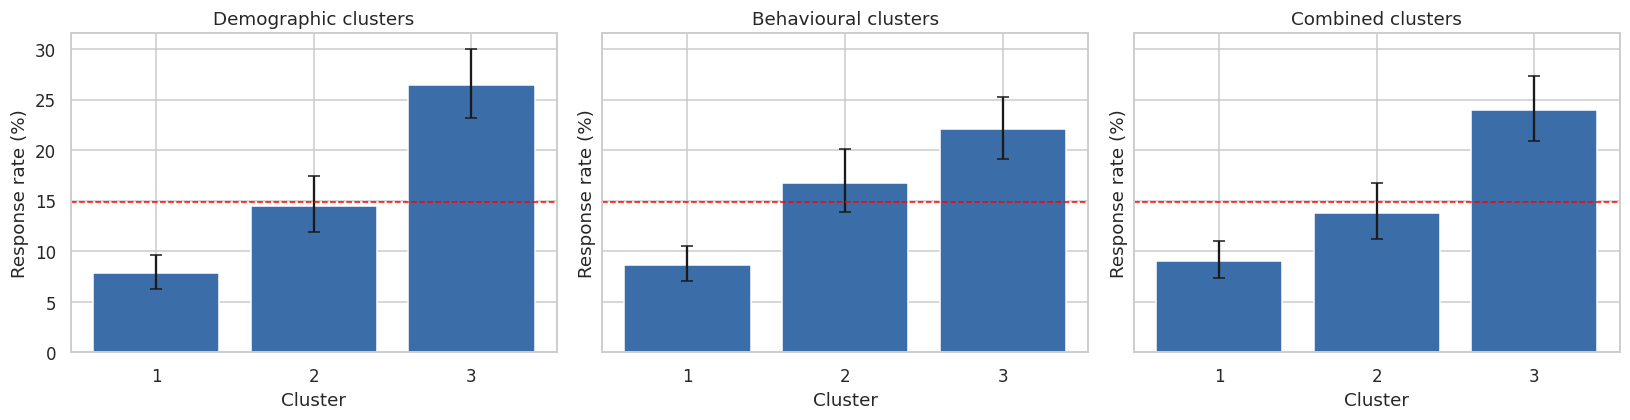

In [17]:
def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z * z / n; c = (p + z * z / (2 * n)) / den; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return c - h, c + h
def cramers_v(a, b):
    t = pd.crosstab(a, b); chi2, p, _, _ = stats.chi2_contingency(t, correction=False)
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1))), p
erows = []; fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, SETS):
    g = LAB[(name, "KMeans")]; d = pd.DataFrame({"g": g, "r": df["Response"].values})
    s = d.groupby("g").r.agg(["sum", "count"]); rate = s["sum"] / s["count"]
    ci = np.array([wilson(a, b) for a, b in zip(s["sum"], s["count"])])
    ax.bar(s.index.astype(str), rate * 100, yerr=[(rate - ci[:, 0]) * 100, (ci[:, 1] - rate) * 100], color="#3B6EA8", capsize=4)
    ax.axhline(df.Response.mean() * 100, color="red", ls="--", lw=1); ax.set_title(f"{name} clusters"); ax.set_xlabel("Cluster"); ax.set_ylabel("Response rate (%)")
    v, p = cramers_v(g, df["Response"].values)
    erows.append({"Segmentation": name, "k": K_USE[name], "Min response %": rate.min() * 100, "Max response %": rate.max() * 100, "Response spread (pp)": (rate.max() - rate.min()) * 100,
                  "Cramers V (Response)": v, "chi2 p": p, "eta2 (Campaigns_Accepted)": eta_sq(df["Campaigns_Accepted"], g), "eta2 (Total_Spend)": eta_sq(df["Total_Spend"], g)})
save_fig("F7_response_by_cluster")
T_EXT = pd.DataFrame(erows).set_index("Segmentation"); save_table(T_EXT, "T14_external_validation"); print(T_EXT.round(4).to_string())
print("Overall response rate:", round(df.Response.mean() * 100, 2), "%")

### 14b. Is the difference in external validity real? Bootstrap CIs (1,000 resamples of customers, labels held fixed)

In [18]:
rng = np.random.default_rng(SEED); resp = df["Response"].values; n = len(resp); BV = {k: [] for k in ("Demographic", "Behavioural", "Combined")}
for _ in range(1000):
    i = rng.integers(0, n, n)
    for k in BV: BV[k].append(cramers_v(LAB[(k, "KMeans")][i], resp[i])[0])
BV = {k: np.array(v) for k, v in BV.items()}
diff = BV["Demographic"] - BV["Behavioural"]
T_BOOT = pd.DataFrame({k: {"V (point)": cramers_v(LAB[(k, "KMeans")], resp)[0], "95% CI low": np.percentile(v, 2.5), "95% CI high": np.percentile(v, 97.5)} for k, v in BV.items()}).T
save_table(T_BOOT, "T14b_bootstrap_V"); print(T_BOOT.round(3).to_string())
print(f"V(Demographic) - V(Behavioural): mean {diff.mean():.3f}, 95% CI [{np.percentile(diff, 2.5):.3f}, {np.percentile(diff, 97.5):.3f}]; share of resamples D > B: {(diff > 0).mean():.3f}")

             V (point)  95% CI low  95% CI high
Demographic      0.218       0.176        0.262
Behavioural      0.165       0.129        0.206
Combined         0.178       0.139        0.222
V(Demographic) - V(Behavioural): mean 0.053, 95% CI [0.020, 0.083]; share of resamples D > B: 0.999


## 15. Cluster visualisation

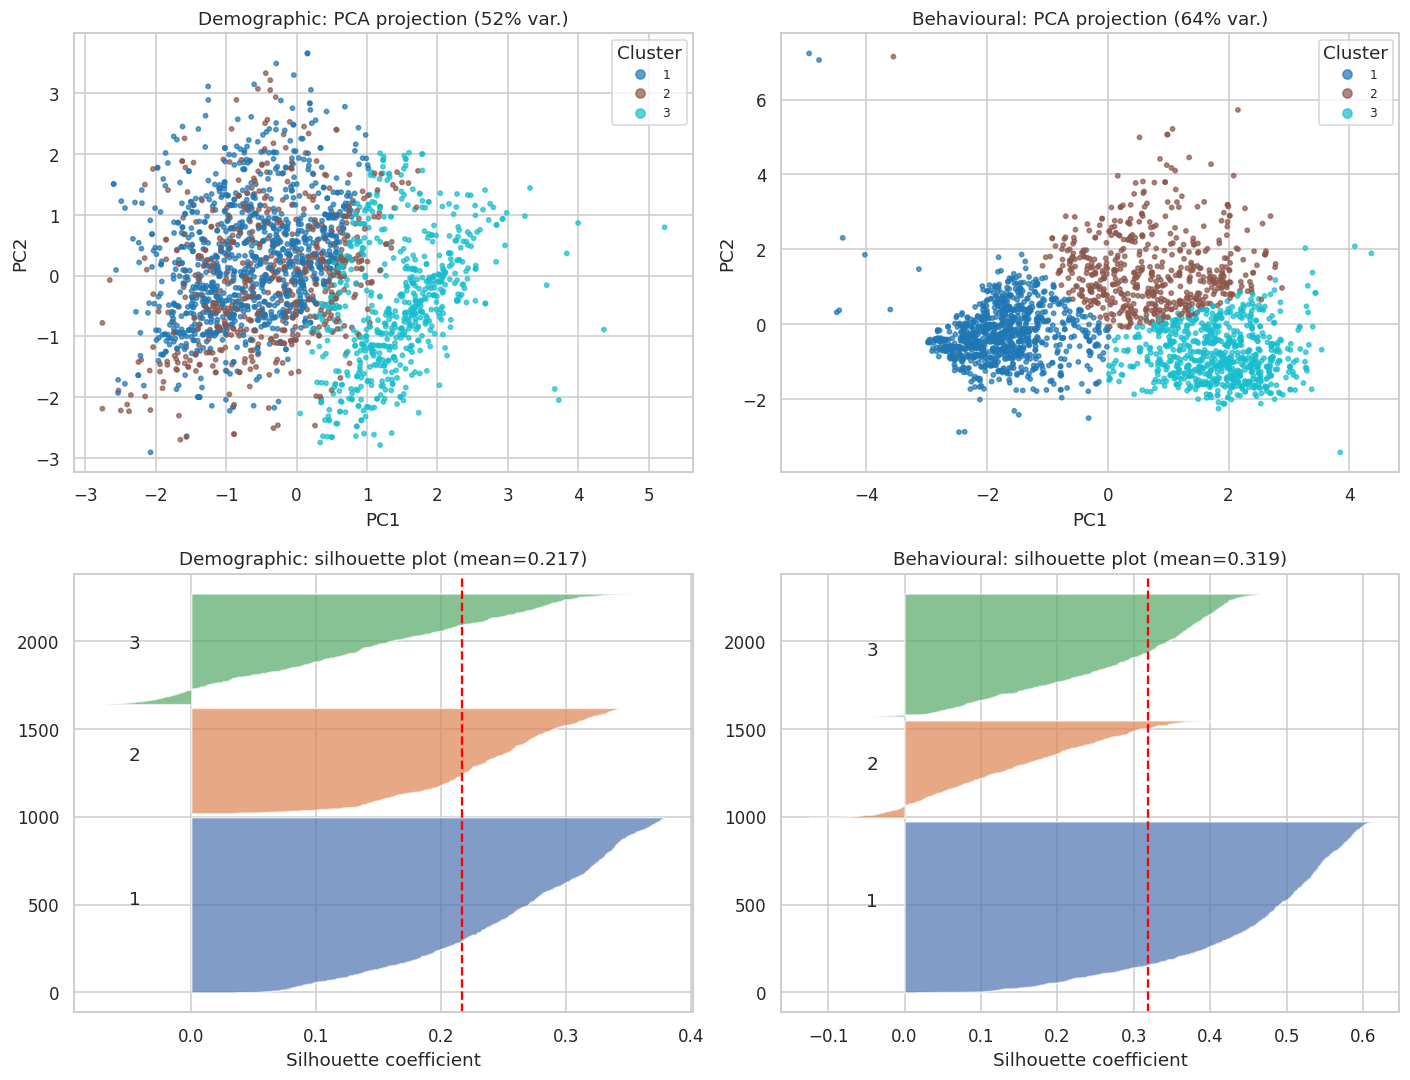

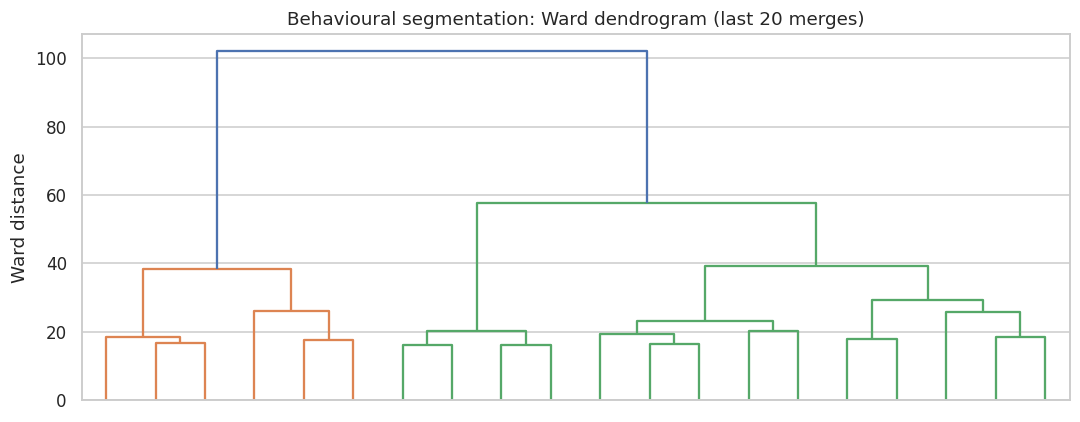

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for r, name in enumerate(("Demographic", "Behavioural")):
    X = XS[name]; p = PCA(n_components=2, random_state=SEED).fit(X); Z = p.transform(X); l = LAB[(name, "KMeans")]
    sc = axes[0, r].scatter(Z[:, 0], Z[:, 1], c=l, cmap="tab10", s=8, alpha=.7); axes[0, r].set_title(f"{name}: PCA projection ({p.explained_variance_ratio_[:2].sum()*100:.0f}% var.)")
    axes[0, r].set_xlabel("PC1"); axes[0, r].set_ylabel("PC2"); axes[0, r].legend(*sc.legend_elements(), title="Cluster", fontsize=8)
    sv = silhouette_samples(X, l); y0 = 0
    for c in np.unique(l):
        s = np.sort(sv[l == c]); axes[1, r].fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, alpha=.7); axes[1, r].text(-0.05, y0 + len(s) / 2, str(c)); y0 += len(s) + 20
    axes[1, r].axvline(sv.mean(), color="red", ls="--"); axes[1, r].set_title(f"{name}: silhouette plot (mean={sv.mean():.3f})"); axes[1, r].set_xlabel("Silhouette coefficient")
save_fig("F8_cluster_viz")
Z = linkage(XS["Behavioural"], "ward"); plt.figure(figsize=(10, 4)); dendrogram(Z, truncate_mode="lastp", p=20, no_labels=True); plt.title("Behavioural segmentation: Ward dendrogram (last 20 merges)"); plt.ylabel("Ward distance")
save_fig("F9_dendrogram")

## 16. Robustness / sensitivity checks (K-Means at the selected k; ARI vs main solution on shared rows)

In [20]:
def run_variant(label, basis, dfx, cols, pca_var=None):
    k = K_USE[basis]; X = build_X(dfx, cols, pca_var); l = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(X)
    shared = df.index.intersection(dfx.index); main = pd.Series(LAB[(basis, "KMeans")], index=df.index).loc[shared]
    return {"Segmentation": basis, "Variant": label, "k": k, "n": len(dfx), "Silhouette (own space)": silhouette_score(X, l), "Davies-Bouldin (own space)": davies_bouldin_score(X, l),
            "ARI vs main": adjusted_rand_score(main, pd.Series(l, index=dfx.index).loc[shared])}

key = [c for c in raw.columns if c != "ID"]
dedup = df[~raw.loc[df.index, key].duplicated()]
dropna_ = df[df["Income"].notna()]
vrows = []
for basis, cols in (("Demographic", DEMO), ("Behavioural", BEHAV)):
    vrows.append(run_variant("Main specification", basis, df, cols))
    vrows.append(run_variant("Duplicate (ex-ID) records removed", basis, dedup, cols))
    vrows.append(run_variant("Rows with missing Income dropped (no imputation)", basis, dropna_, cols))
    vrows.append(run_variant("PCA retaining 95% variance before K-Means", basis, df, cols, pca_var=0.95))
vrows.append(run_variant("Six spend categories (log1p) instead of Total_Spend", "Behavioural", df.assign(**{c + "_log": np.log1p(df[c]) for c in spend_cols}),
                         [c for c in BEHAV if c != "Total_Spend_log"] + [c + "_log" for c in spend_cols]))
vrows.append(run_variant("Education excluded", "Demographic", df, [c for c in DEMO if c != "Edu_ord"]))
T_ROB = pd.DataFrame(vrows).set_index(["Segmentation", "Variant"]); save_table(T_ROB, "T15_robustness"); print(T_ROB.round(3).to_string())
print("\nNote: silhouette/DB across variants are computed in different feature spaces; compare ARI vs main for structural consistency.")

                                                                  k     n  Silhouette (own space)  Davies-Bouldin (own space)  ARI vs main
Segmentation Variant                                                                                                                      
Demographic  Main specification                                   3  2232                   0.217                       1.606        1.000
             Duplicate (ex-ID) records removed                    3  2050                   0.216                       1.606        0.980
             Rows with missing Income dropped (no imputation)     3  2208                   0.216                       1.603        0.979
             PCA retaining 95% variance before K-Means            3  2232                   0.217                       1.606        1.000
Behavioural  Main specification                                   3  2232                   0.319                       1.434        1.000
             Duplicate (ex-

## 17. Sensitivity: Demographic segmentation at its own rule-selected k

In [21]:
kd = K_SEL["Demographic"]; Xd = XS["Demographic"]
ref_d = relabel(KMeans(n_clusters=kd, n_init=50, random_state=SEED).fit_predict(Xd), df["Income"])
m_, s_, mn_ = seed_stability(Xd, kd); sub_d = subsample_stability(Xd, kd, ref_d, "KMeans")
vv, pp = cramers_v(ref_d, df["Response"].values)
T_SENS = pd.DataFrame([{"Segmentation": f"Demographic k={kd}", "Silhouette": silhouette_score(Xd, ref_d), "Davies-Bouldin": davies_bouldin_score(Xd, ref_d),
    "Seed ARI (mean)": m_, "Subsample ARI (mean)": sub_d.mean(), "Cramers V (Response)": vv, "eta2 (Total_Spend)": eta_sq(df["Total_Spend"], ref_d),
    "ARI vs Behavioural k=3": adjusted_rand_score(ref_d, LAB[("Behavioural", "KMeans")])}]).set_index("Segmentation")
save_table(T_SENS, "T16_sensitivity_demographic_ownk"); print(T_SENS.round(3).to_string())
prof8 = df.assign(Cluster=ref_d).groupby("Cluster")[["Age","Income","Edu_ord","Partnered","Total_Children","Total_Spend","Response"]].mean(); save_table(prof8, "T17_profile_demographic_k8"); print(prof8.round(2).to_string())

                 Silhouette  Davies-Bouldin  Seed ARI (mean)  Subsample ARI (mean)  Cramers V (Response)  eta2 (Total_Spend)  ARI vs Behavioural k=3
Segmentation                                                                                                                                        
Demographic k=8       0.251           1.232            0.641                 0.894                 0.234               0.478                   0.121
           Age    Income  Edu_ord  Partnered  Total_Children  Total_Spend  Response
Cluster                                                                            
1        35.49  31414.89     2.23       1.00            0.86       178.21      0.09
2        37.52  34672.71     2.12       0.00            1.04       200.11      0.11
3        47.93  44792.40     2.41       0.97            2.16       264.77      0.07
4        48.62  46366.98     3.71       0.00            1.55       362.86      0.21
5        48.83  53274.11     3.78       1.00     

## 18. Summary of key numbers (generated from the run above)

In [22]:
print("Rows used:", len(df))
print("k selected:", K_USE)
print(T_MAIN[["k", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz", "Smallest cluster %"]].round(3).to_string())
print(T_EXT.round(4).to_string())

Rows used: 2232
k selected: {'Demographic': 3, 'Behavioural': 3, 'Combined': 3}
                        k  Silhouette  Davies-Bouldin  Calinski-Harabasz  Smallest cluster %
Segmentation Algorithm                                                                      
Demographic  KMeans     3       0.217           1.606            538.257              26.971
             Ward       3       0.183           1.767            466.953              22.088
Behavioural  KMeans     3       0.319           1.434            995.730              24.866
             Ward       3       0.324           1.236            871.342               9.409
Combined     KMeans     3       0.207           1.830            623.929              26.658
             Ward       3       0.193           1.881            575.821              21.147
              k  Min response %  Max response %  Response spread (pp)  Cramers V (Response)  chi2 p  eta2 (Campaigns_Accepted)  eta2 (Total_Spend)
Segmentation                 